<a href="https://colab.research.google.com/github/Privespoli/eda_mujeres_tech/blob/main/EDA_mujeres_tch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset: indicadores públicos de empleo, educación o participación de mujeres en ámbitos tecnológicos.
Preguntas que pueden investigar:
● ¿Cómo varía la participación femenina entre países?
● ¿Qué cambios se observan a lo largo del tiempo?
● ¿Qué diferencias aparecen entre indicadores?
● ¿Qué información falta para entender mejor las diferencias?
Qué pueden enseñar: comparación temporal, selección de países, gráficos de líneas e interpretación responsable.
Dificultad: media. Conviene elegir un único indicador y una tabla sencilla.
Banco Mundial: datos públicos

In [ ]:
#Importar biblios

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [ ]:
#Leer archivo

df = pd.read_csv('datos.csv')

print("Dimensiones del dataset:", df.shape)

df.head()

Dimensiones del dataset: (1412, 10)


,DATAFLOW,LAST UPDATE,freq,unit,sex,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2016,17.1,NaN,NaN
1,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2017,15.7,e,NaN
2,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2018,18.4,NaN,NaN
3,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2019,20.4,NaN,NaN
4,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2020,20.3,NaN,NaN


In [ ]:
# Información general del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1412 entries, 0 to 1411
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATAFLOW     1412 non-null   object 
 1   LAST UPDATE  1412 non-null   object 
 2   freq         1412 non-null   object 
 3   unit         1412 non-null   object 
 4   sex          1412 non-null   object 
 5   geo          1412 non-null   object 
 6   TIME_PERIOD  1412 non-null   int64  
 7   OBS_VALUE    1406 non-null   float64
 8   OBS_FLAG     938 non-null    object 
 9   CONF_STATUS  0 non-null      float64
dtypes: float64(2), int64(1), object(7)
memory usage: 110.4+ KB


In [ ]:
# Comprobar filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


In [ ]:
# Contar valores ausentes por columna
print("Valores ausentes por columna:")
print(df.isnull().sum())

Valores ausentes por columna:
DATAFLOW          0
LAST UPDATE       0
freq              0
unit              0
sex               0
geo               0
TIME_PERIOD       0
OBS_VALUE         6
OBS_FLAG        474
CONF_STATUS    1412
dtype: int64


In [ ]:
# Categorías de sexo
print("Sexo:")
print(df["sex"].unique())

# Unidades de medida
print("\nUnidades:")
print(df["unit"].unique())

# Años disponibles
print("\nAños:")
print(sorted(df["TIME_PERIOD"].unique()))

# Países y regiones
print("\nNúmero de países o regiones:")
print(df["geo"].nunique())

Sexo:
['Females' 'Males']

Unidades:
['Percentage' 'Thousand persons']

Años:
[np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Número de países o regiones:
37


In [ ]:
# Seleccionar únicamente mujeres y porcentajes
df_mujeres = df[
    (df["sex"] == "Females") &
    (df["unit"] == "Percentage")
].copy()

# Mostrar las dimensiones del nuevo dataset
print("Dimensiones del dataset filtrado:", df_mujeres.shape)

# Mostrar las primeras filas
df_mujeres.head()

Dimensiones del dataset filtrado: (353, 10)


,DATAFLOW,LAST UPDATE,freq,unit,sex,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2016,17.1,NaN,NaN
1,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2017,15.7,e,NaN
2,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2018,18.4,NaN,NaN
3,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2019,20.4,NaN,NaN
4,ESTAT:ISOC_SKS_ITSPS$DEFAULTVIEW(1.0),17/04/26 23:00:00,Annual,Percentage,Females,Austria,2020,20.3,NaN,NaN


In [ ]:
# Comprobar las categorías después del filtrado
print("Sexo:", df_mujeres["sex"].unique())
print("Unidad:", df_mujeres["unit"].unique())

print("Número de países o regiones:",
      df_mujeres["geo"].nunique())

print("Años disponibles:",
      sorted(df_mujeres["TIME_PERIOD"].unique()))

Sexo: ['Females']
Unidad: ['Percentage']
Número de países o regiones: 37
Años disponibles: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [ ]:
# Comprobar valores ausentes en el dataset filtrado
print("Valores ausentes por columna:")
print(df_mujeres.isnull().sum())

# Mostrar los registros sin valor en el indicador
df_mujeres[df_mujeres["OBS_VALUE"].isnull()][
    ["geo", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]
]

Valores ausentes por columna:
DATAFLOW         0
LAST UPDATE      0
freq             0
unit             0
sex              0
geo              0
TIME_PERIOD      0
OBS_VALUE        3
OBS_FLAG        86
CONF_STATUS    353
dtype: int64


,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG
224,Montenegro,2016,NaN,u
227,Montenegro,2019,NaN,u
228,Montenegro,2020,NaN,u


In [ ]:
# Seleccionar las columnas necesarias para el EDA

df_eda = df_mujeres[
    ["geo", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]
].copy()

# Renombrar las columnas para facilitar la lectura

df_eda = df_eda.rename(columns={
    "geo": "pais",
    "TIME_PERIOD": "anio",
    "OBS_VALUE": "porcentaje",
    "OBS_FLAG": "nota"
})

# Mostrar las dimensiones de la nueva tabla

print("Dimensiones de la tabla de trabajo:", df_eda.shape)

# Mostrar las primeras filas

df_eda.head(10)

Dimensiones de la tabla de trabajo: (353, 4)


,pais,anio,porcentaje,nota
0,Austria,2016,17.1,NaN
1,Austria,2017,15.7,e
2,Austria,2018,18.4,NaN
3,Austria,2019,20.4,NaN
4,Austria,2020,20.3,NaN
5,Austria,2021,19.0,b
6,Austria,2022,19.3,NaN
7,Austria,2023,19.5,NaN
8,Austria,2024,21.1,e
9,Austria,2025,19.7,e


In [ ]:
# Contar valores ausentes en el indicador

valores_ausentes = df_eda["porcentaje"].isnull().sum()

total_registros = len(df_eda)

porcentaje_ausentes = (
    valores_ausentes / total_registros
) * 100

print("Valores ausentes:", valores_ausentes)

print("Total de registros:", total_registros)

print(
    f"Porcentaje de valores ausentes: {porcentaje_ausentes:.2f}%"
)

Valores ausentes: 3
Total de registros: 353
Porcentaje de valores ausentes: 0.85%


In [ ]:
# Comprobar duplicados por país y año

duplicados_pais_anio = df_eda.duplicated(
    subset=["pais", "anio"]
).sum()

print(
    "Registros duplicados por país y año:",
    duplicados_pais_anio
)

Registros duplicados por país y año: 0


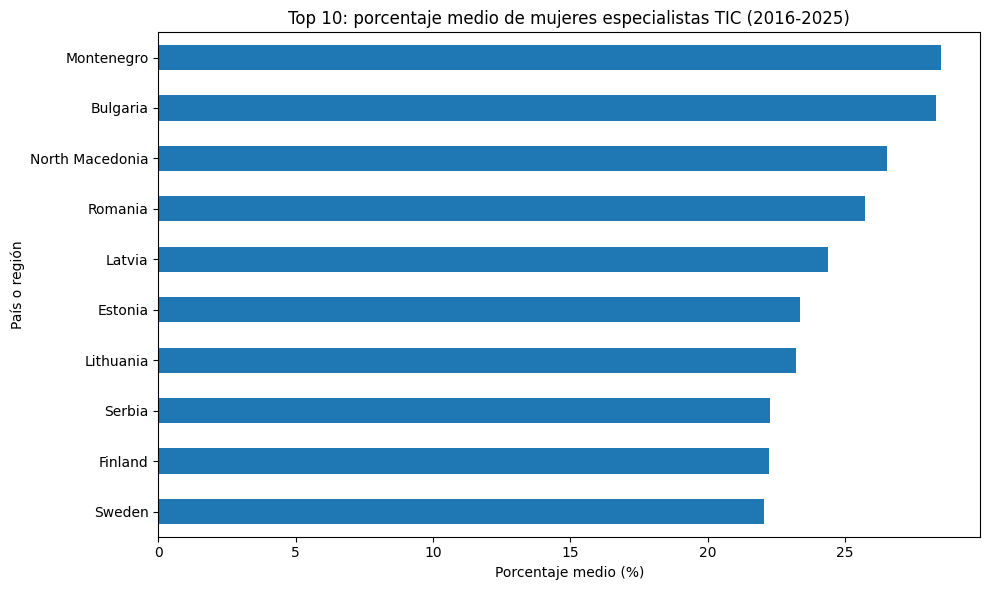

In [ ]:
# Calcular el porcentaje promedio por país y obtener los 10 más altos
promedio_paises = df_eda.groupby("pais")["porcentaje"].mean().sort_values(ascending=False)
top_10 = promedio_paises.head(10).sort_values()

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
top_10.plot(kind="barh")

plt.title(
    "Top 10: porcentaje medio de mujeres especialistas TIC (2016-2025)"
)
plt.xlabel("Porcentaje medio (%)")
plt.ylabel("País o región")

plt.tight_layout()
plt.show()

El gráfico de barras permite observar diferencias entre los países europeos en el porcentaje de mujeres entre los especialistas en tecnologías de la información y la comunicación (TIC). Durante el periodo analizado, Montenegro y Bulgaria presentan algunos de los promedios más elevados, mientras que otros países muestran valores inferiores.

Esta comparación inicial sugiere que la participación femenina en el sector TIC no es homogénea entre los países. Sin embargo, para interpretar correctamente estas diferencias, es necesario considerar la disponibilidad de datos, las posibles diferencias metodológicas y la evolución temporal de cada país.

In [ ]:
# Mostrar todos los países y regiones disponibles

print(sorted(df_eda["pais"].unique()))

['Austria', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'European Union - 27 countries (from 2020)', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Montenegro', 'Netherlands', 'North Macedonia', 'Norway', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Türkiye', 'United Kingdom']


In [ ]:
# Contar los años con datos disponibles para cada país o región

observaciones_pais = (
    df_eda.groupby("pais")["porcentaje"]
    .agg(["count", "min", "max"])
    .sort_values("count")
)

observaciones_pais

,count,min,max
pais,,,
Montenegro,2,27.6,29.4
United Kingdom,4,16.5,17.6
Bosnia and Herzegovina,5,17.8,26.5
Iceland,9,16.9,23.8
Croatia,10,13.9,21.4
Cyprus,10,17.8,23.7
Czechia,10,9.7,13.0
Belgium,10,14.1,19.6
Denmark,10,19.9,22.8


In [ ]:
# Buscar España y la Unión Europea en el dataset

df_eda[
    df_eda["pais"].str.contains(
        "Spain|España|European Union",
        case=False,
        na=False
    )
]["pais"].unique()

array(['Spain', 'European Union - 27 countries (from 2020)'], dtype=object)

In [ ]:
# Seleccionar España y la Unión Europea

paises_seleccionados = [
    "Spain",
    "European Union - 27 countries (from 2020)"
]

df_evolucion = df_eda[
    df_eda["pais"].isin(paises_seleccionados)
].copy()

# Ordenar por país y año

df_evolucion = df_evolucion.sort_values(
    ["pais", "anio"]
)

# Mostrar la evolución anual

df_evolucion[["pais", "anio", "porcentaje"]]

,pais,anio,porcentaje
115,European Union - 27 countries (from 2020),2016,17.0
116,European Union - 27 countries (from 2020),2017,17.2
117,European Union - 27 countries (from 2020),2018,17.2
118,European Union - 27 countries (from 2020),2019,17.8
119,European Union - 27 countries (from 2020),2020,18.4
120,European Union - 27 countries (from 2020),2021,19.1
121,European Union - 27 countries (from 2020),2022,18.9
122,European Union - 27 countries (from 2020),2023,19.4
123,European Union - 27 countries (from 2020),2024,19.5
124,European Union - 27 countries (from 2020),2025,19.5


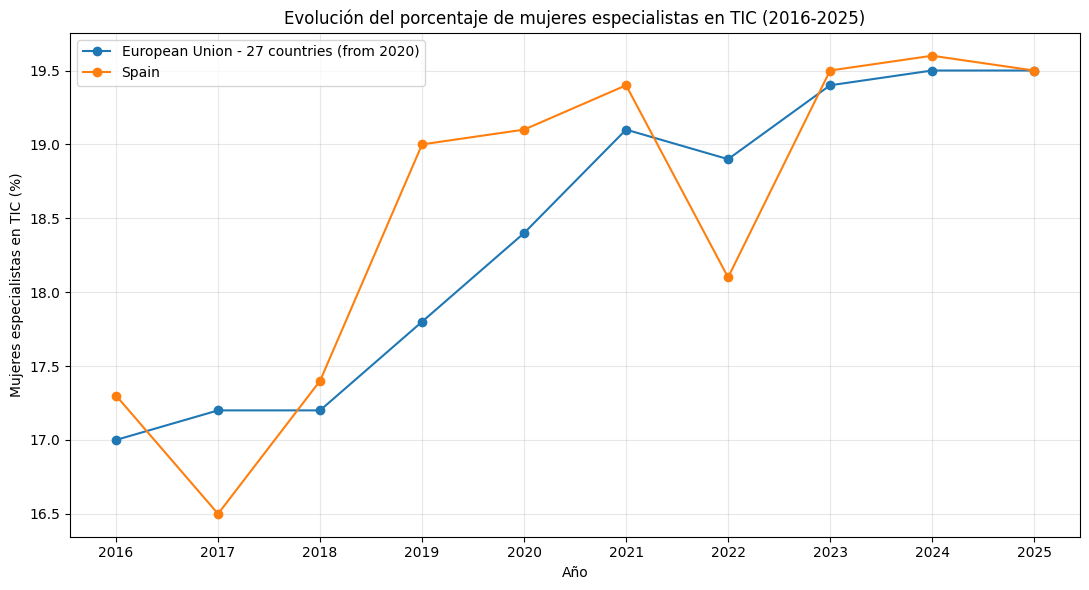

In [ ]:
# Crear una tabla con los años en filas y países en columnas

tabla_evolucion = df_evolucion.pivot(
    index="anio",
    columns="pais",
    values="porcentaje"
)

# Crear el gráfico

plt.figure(figsize=(11, 6))

for pais in tabla_evolucion.columns:
    plt.plot(
        tabla_evolucion.index,
        tabla_evolucion[pais],
        marker="o",
        label=pais
    )

plt.title(
    "Evolución del porcentaje de mujeres especialistas en TIC (2016-2025)"
)

plt.xlabel("Año")
plt.ylabel("Mujeres especialistas en TIC (%)")

plt.xticks(range(2016, 2026))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Calcular la diferencia entre España y la Unión Europea

tabla_evolucion["Diferencia España - UE"] = (
    tabla_evolucion["Spain"]
    - tabla_evolucion[
        "European Union - 27 countries (from 2020)"
    ]
)

display(tabla_evolucion.round(2))

pais,European Union - 27 countries (from 2020),Spain,Diferencia España - UE
anio,,,
2016,17.0,17.3,0.3
2017,17.2,16.5,-0.7
2018,17.2,17.4,0.2
2019,17.8,19.0,1.2
2020,18.4,19.1,0.7
2021,19.1,19.4,0.3
2022,18.9,18.1,-0.8
2023,19.4,19.5,0.1
2024,19.5,19.6,0.1


In [ ]:
# Crear una tabla con todos los países y años

tabla_paises = df_eda.pivot(
    index="pais",
    columns="anio",
    values="porcentaje"
)

# Ordenar los países alfabéticamente
tabla_paises = tabla_paises.sort_index()

# Mostrar la tabla completa
display(tabla_paises.round(2))

anio,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pais,,,,,,,,,,
Austria,17.1,15.7,18.4,20.4,20.3,19.0,19.3,19.5,21.1,19.7
Belgium,14.1,15.6,16.8,17.2,17.4,19.6,18.7,19.4,19.0,17.6
Bosnia and Herzegovina,NaN,NaN,NaN,NaN,NaN,17.8,24.3,19.5,20.5,26.5
Bulgaria,29.1,29.2,30.1,28.3,28.4,28.2,28.9,29.1,27.0,25.0
Croatia,13.9,14.6,17.5,21.0,19.1,21.4,13.9,17.3,21.4,18.4
Cyprus,23.7,18.2,18.9,17.9,17.8,19.2,21.7,23.7,23.7,20.1
Czechia,10.0,10.1,9.7,10.2,10.3,10.0,10.9,12.4,13.0,12.9
Denmark,20.7,19.9,20.1,21.3,22.6,22.8,22.0,22.6,21.2,21.1
Estonia,20.5,20.3,22.5,23.8,22.7,22.6,24.5,26.8,27.6,22.5


In [ ]:
# Estadísticas descriptivas por país

resumen_paises = (
    df_eda.groupby("pais")["porcentaje"]
    .agg(
        promedio="mean",
        minimo="min",
        maximo="max",
        años_con_datos="count"
    )
    .sort_values("promedio", ascending=False)
)

display(resumen_paises.round(2))

,promedio,minimo,maximo,años_con_datos
pais,,,,
Montenegro,28.50,27.6,29.4,2
Bulgaria,28.33,25.0,30.1,10
North Macedonia,26.55,22.6,31.7,10
Romania,25.73,23.4,27.8,10
Latvia,24.40,20.5,27.0,10
Estonia,23.38,20.3,27.6,10
Lithuania,23.22,18.2,25.9,10
Serbia,22.27,19.3,24.9,10
Finland,22.23,19.9,24.3,10


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Paleta de colores
colores = {
    "azul": "#4361EE",
    "turquesa": "#2EC4B6",
    "violeta": "#7B2CBF",
    "coral": "#FF6B6B",
    "amarillo": "#FFBE0B",
    "oscuro": "#253047"
}

# Estilo general
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlecolor"] = colores["oscuro"]
plt.rcParams["axes.labelcolor"] = colores["oscuro"]
plt.rcParams["font.family"] = "DejaVu Sans"

# Preparar los datos
datos = df_eda.copy()

datos["anio"] = pd.to_numeric(
    datos["anio"], errors="coerce"
)

datos["porcentaje"] = pd.to_numeric(
    datos["porcentaje"], errors="coerce"
)

# Nombre del agregado de la UE que aparece en tu archivo
nombre_ue = "European Union - 27 countries (from 2020)"

# Excluir la UE de las comparaciones entre países individuales
paises = datos[
    datos["pais"] != nombre_ue
].copy()

# Resumen por país
resumen = (
    paises.groupby("pais")["porcentaje"]
    .agg(["mean", "std", "count"])
    .rename(columns={
        "mean": "promedio",
        "std": "desviacion",
        "count": "anios_con_datos"
    })
)

# Para comparar países, exigimos al menos 8 observaciones
resumen_comparable = resumen[
    resumen["anios_con_datos"] >= 8
].copy()

print("Países con al menos 8 años de datos:",
      len(resumen_comparable))

print("¡Estilo y datos preparados!")

Países con al menos 8 años de datos: 33
¡Estilo y datos preparados!


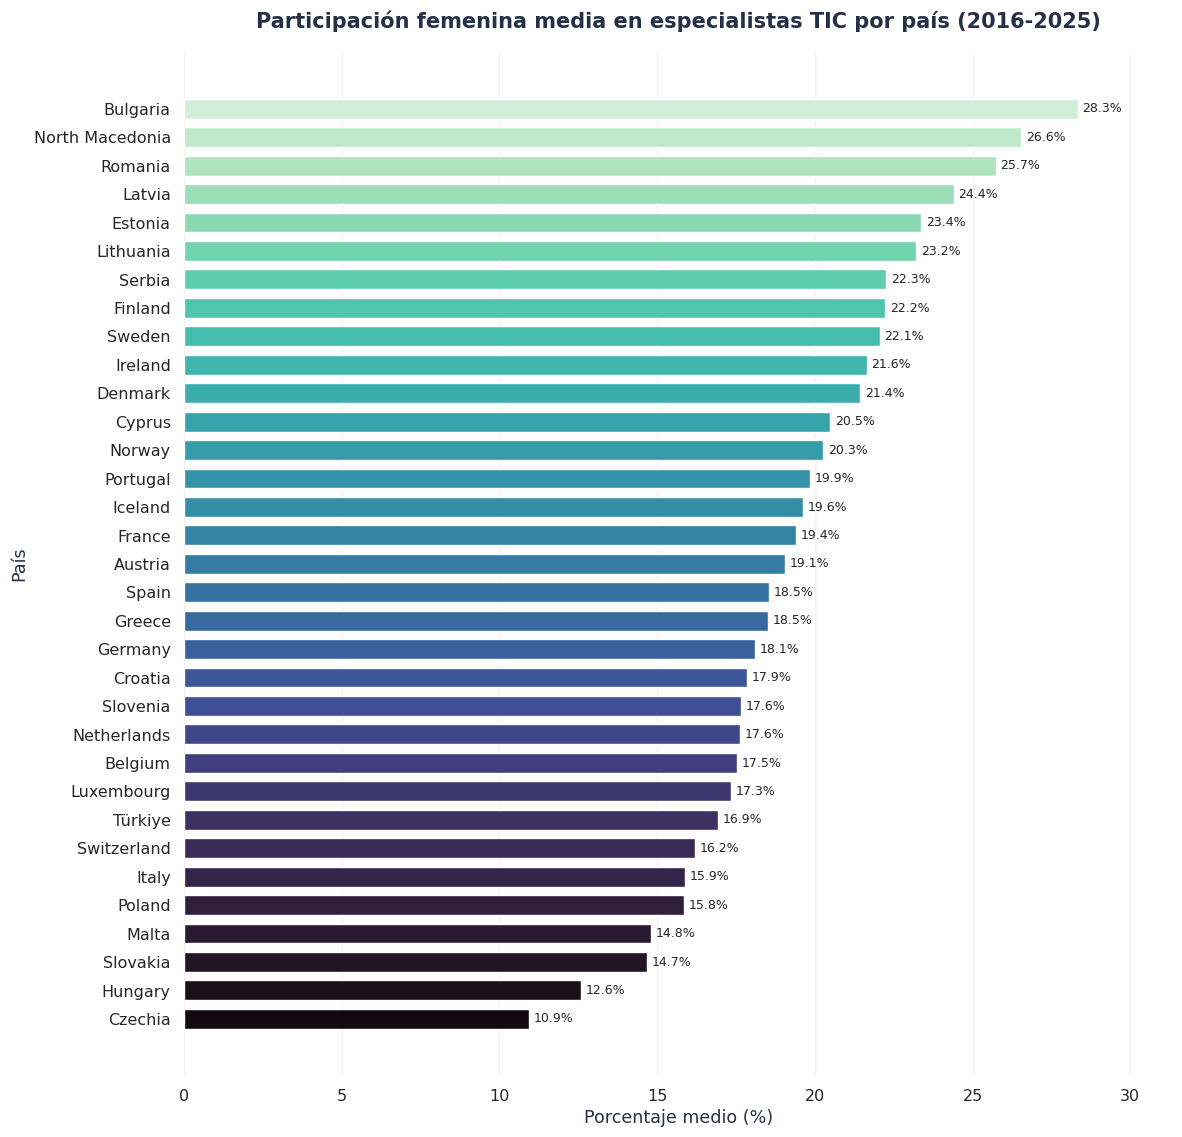

In [ ]:
# Seleccionar todos los países con al menos 8 años de datos
todos_paises = (
    resumen_comparable
    .sort_values("promedio", ascending=True)
)

# Ajustar la altura según el número de países
fig, ax = plt.subplots(
    figsize=(12, max(8, len(todos_paises) * 0.35))
)

# Crear una paleta de colores
colores_barras = sns.color_palette(
    "mako",
    n_colors=len(todos_paises)
)

# Crear gráfico de barras horizontales
barras = ax.barh(
    todos_paises.index,
    todos_paises["promedio"],
    color=colores_barras,
    height=0.7
)

# Añadir el porcentaje al final de cada barra
for barra, valor in zip(barras, todos_paises["promedio"]):
    ax.text(
        valor + 0.15,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.1f}%",
        va="center",
        fontsize=9
    )

# Título y etiquetas
ax.set_title(
    "Participación femenina media en especialistas TIC por país (2016-2025)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Porcentaje medio (%)")
ax.set_ylabel("País")

# Ajustar el eje horizontal
ax.set_xlim(
    0,
    todos_paises["promedio"].max() + 3
)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

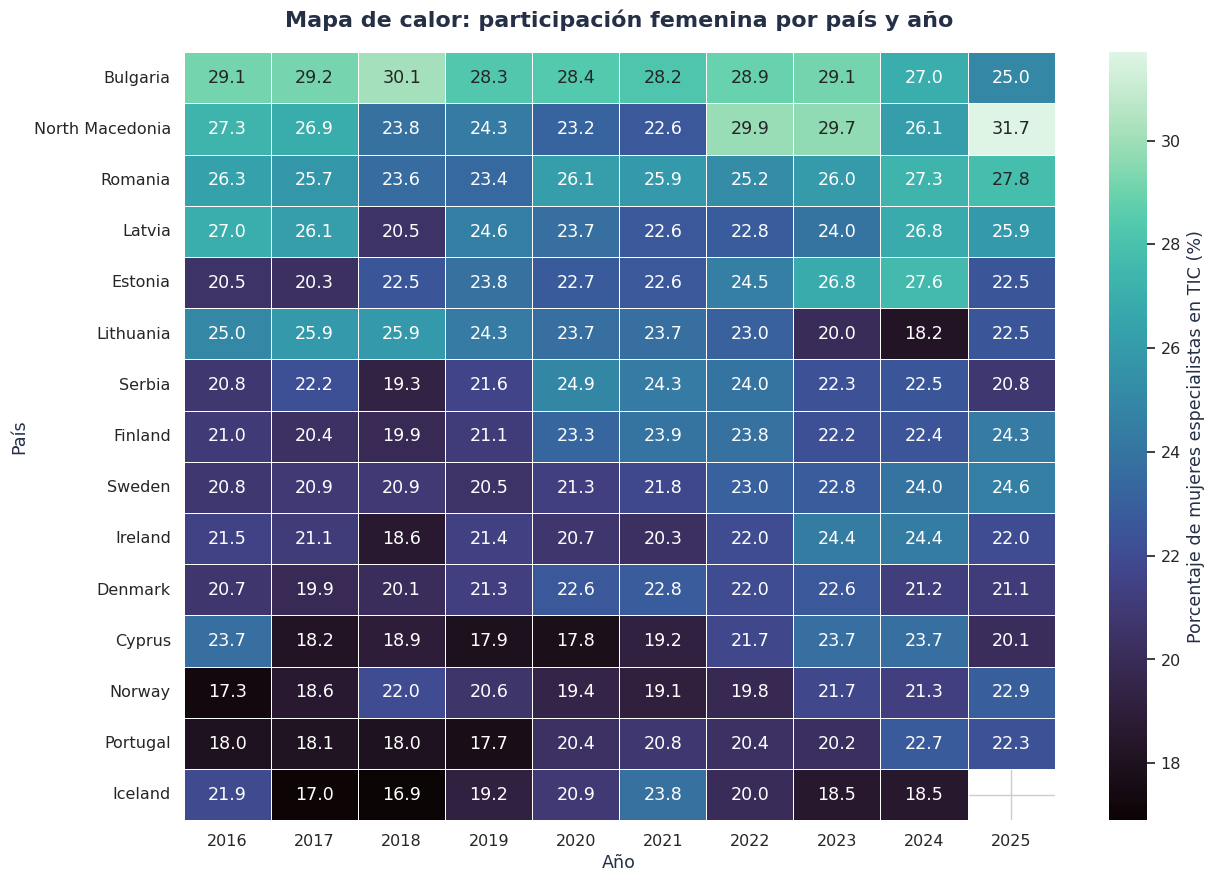

In [ ]:
# Seleccionar los 15 países con mayor promedio
paises_heatmap = (
    resumen_comparable
    .sort_values("promedio", ascending=False)
    .head(15)
    .index
)

datos_heatmap = paises[
    paises["pais"].isin(paises_heatmap)
]

matriz = datos_heatmap.pivot(
    index="pais",
    columns="anio",
    values="porcentaje"
)

# Ordenar los países por promedio
orden = (
    resumen_comparable.loc[
        matriz.index, "promedio"
    ].sort_values(ascending=False).index
)

matriz = matriz.loc[orden]

fig, ax = plt.subplots(figsize=(13, 9))

sns.heatmap(
    matriz,
    cmap="mako",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Porcentaje de mujeres especialistas en TIC (%)"
    },
    ax=ax
)

ax.set_title(
    "Mapa de calor: participación femenina por país y año",
    fontsize=16,
    pad=18
)

ax.set_xlabel("Año")
ax.set_ylabel("País")

plt.tight_layout()
plt.show()

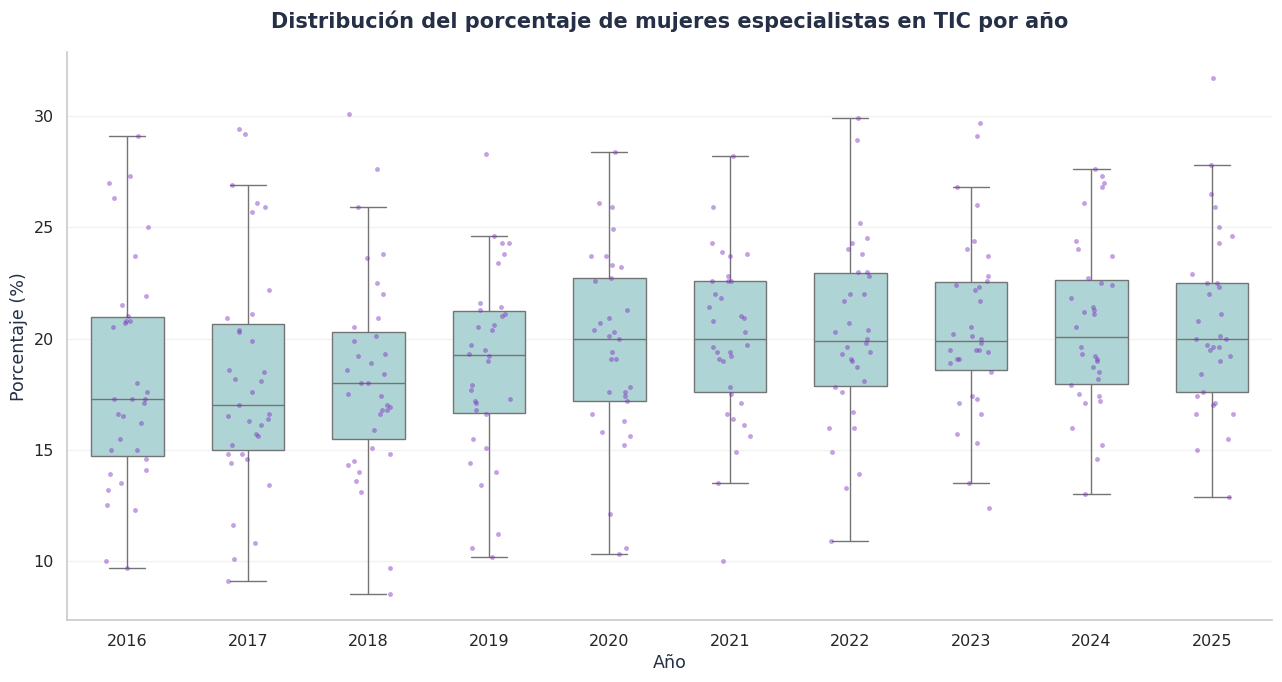

In [ ]:
fig, ax = plt.subplots(figsize=(13, 7))

sns.boxplot(
    data=paises,
    x="anio",
    y="porcentaje",
    color="#A8DADC",
    width=0.6,
    showfliers=False,
    ax=ax
)

# Añadir observaciones individuales
sns.stripplot(
    data=paises,
    x="anio",
    y="porcentaje",
    color=colores["violeta"],
    alpha=0.45,
    size=3.5,
    jitter=0.18,
    ax=ax
)

ax.set_title(
    "Distribución del porcentaje de mujeres especialistas en TIC por año",
    fontsize=15,
    pad=18
)

ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje (%)")

ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

¿Cómo interpretar este gráfico?
- La línea central de cada caja representa la mediana.
- La altura de la caja refleja la dispersión del 50 % central de los valores.
- Los puntos representan las observaciones individuales.
- Una caja más alta sugiere una mayor variabilidad entre los países en ese año.
He ocultado los símbolos de los valores extremos del boxplot para evitar que dominen visualmente el gráfico, pero mantenemos las observaciones individuales para poder examinarlas.

Este gráfico considera países individuales, no el agregado de la Unión Europea.

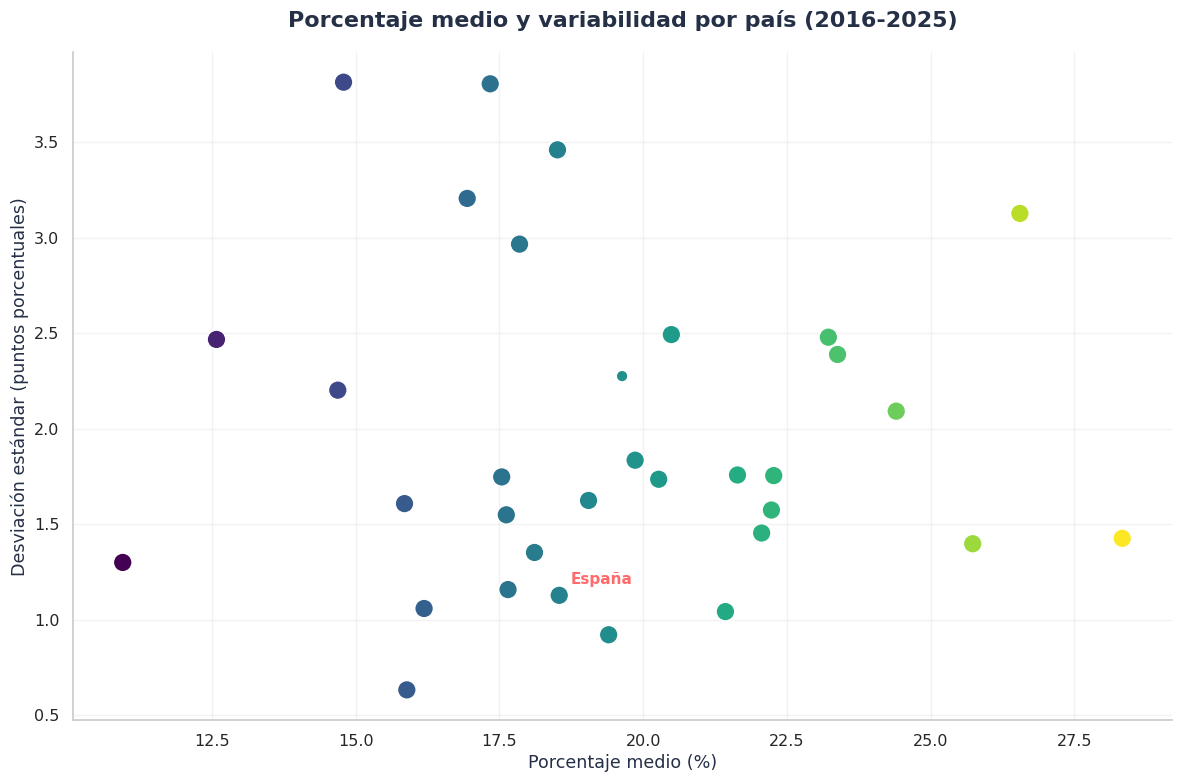

In [ ]:
dispersion = resumen_comparable.dropna(
    subset=["promedio", "desviacion"]
).copy()

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=dispersion,
    x="promedio",
    y="desviacion",
    hue="promedio",
    size="anios_con_datos",
    sizes=(70, 180),
    palette="viridis",
    edgecolor="white",
    linewidth=1,
    legend=False,
    ax=ax
)

# Etiquetar España si está presente
if "Spain" in dispersion.index:
    espana = dispersion.loc["Spain"]

    ax.annotate(
        "España",
        xy=(espana["promedio"], espana["desviacion"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color=colores["coral"]
    )

ax.set_title(
    "Porcentaje medio y variabilidad por país (2016-2025)",
    fontsize=16,
    pad=18
)

ax.set_xlabel("Porcentaje medio (%)")
ax.set_ylabel("Desviación estándar (puntos porcentuales)")

ax.grid(alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

¿Cómo leerlo?
- Puntos más a la derecha: mayor porcentaje medio.
- Puntos más arriba: mayor variabilidad entre los años.
- Puntos abajo y a la derecha: porcentajes medios relativamente altos y menor variabilidad.
La desviación estándar no indica si un país mejora o empeora: mide cuánto fluctúan sus valores alrededor de su media.